# Image-to-Image Translation with cGAN (pix2pix)
**Author:** [Ajim Mujawar]  
**Task 04 - Generative AI**

Build and train **pix2pix**, a conditional GAN that learns to translate an input image into an output image. We translate **architecture label maps -> building facade photos** using the CMP Facade dataset.

- Generator: **U-Net**
- Discriminator: **PatchGAN**
- Loss: GAN loss + 100 x L1 loss

> Use a **GPU runtime** (Colab: Runtime -> Change runtime type -> T4 GPU). 40k steps takes roughly 1-2 hours on a T4. For a quick demo use `STEPS = 2000`.

## 1. Imports

In [1]:
import os, time, datetime, pathlib
import tensorflow as tf
from matplotlib import pyplot as plt
from IPython import display

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


## 2. Load the dataset
Each file is 256x512: two 256x256 images side by side.

Dataset path: C:\Users\ADMIN\.keras\datasets\facades_extracted\facades
Dataset exists: True
Sample image: C:\Users\ADMIN\.keras\datasets\facades_extracted\facades\train\1.jpg
Image shape: (256, 512, 3)


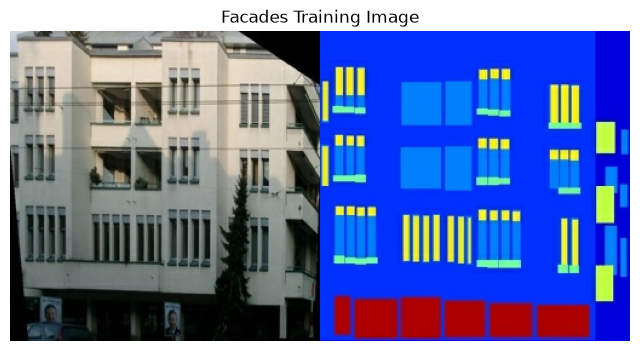

In [3]:

import pathlib
import tensorflow as tf
import matplotlib.pyplot as plt

dataset_name = "facades"

# Use the dataset folder that was already extracted
PATH = pathlib.Path.home() / ".keras" / "datasets" / "facades_extracted" / dataset_name

print("Dataset path:", PATH)
print("Dataset exists:", PATH.exists())

# Find an actual training image instead of assuming its name is 1.jpg
train_images = sorted((PATH / "train").glob("*.jpg"))

if not train_images:
    raise FileNotFoundError(f"No JPG training images found in {PATH / 'train'}")

sample_path = train_images[0]
print("Sample image:", sample_path)

sample_image = tf.io.decode_jpeg(tf.io.read_file(str(sample_path)))

print("Image shape:", sample_image.shape)

plt.figure(figsize=(8, 6))
plt.imshow(sample_image)
plt.title("Facades Training Image")
plt.axis("off")
plt.show()


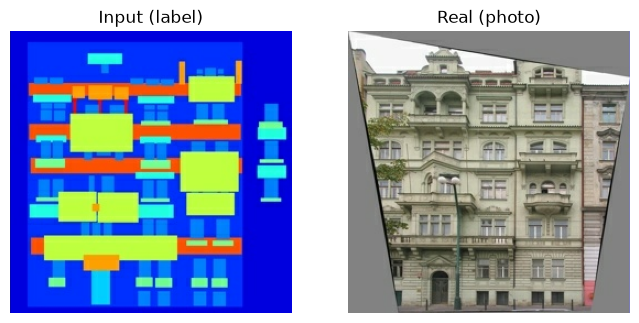

In [4]:
def load(image_file):
    image = tf.io.decode_jpeg(tf.io.read_file(image_file))
    w = tf.shape(image)[1] // 2
    input_image = tf.cast(image[:, w:, :], tf.float32)   # architecture label
    real_image  = tf.cast(image[:, :w, :], tf.float32)   # real facade photo
    return input_image, real_image

inp, re = load(str(PATH / "train/100.jpg"))
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(inp / 255.0); plt.title("Input (label)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(re / 255.0);  plt.title("Real (photo)"); plt.axis("off")
plt.show()

## 3. Preprocessing and augmentation
1. Resize to 286x286 -> 2. random-crop to 256x256 -> 3. random horizontal flip -> 4. normalize to [-1, 1].

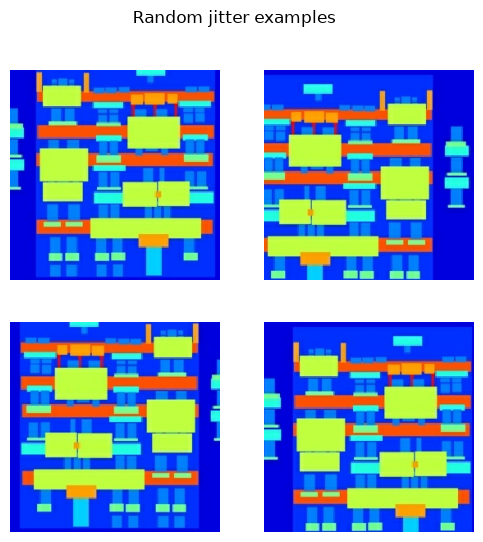

In [5]:
BUFFER_SIZE = 400
BATCH_SIZE = 1
IMG_WIDTH = 256
IMG_HEIGHT = 256

def resize(input_image, real_image, height, width):
    input_image = tf.image.resize(input_image, [height, width], method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    real_image  = tf.image.resize(real_image,  [height, width], method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
    return input_image, real_image

def random_crop(input_image, real_image):
    stacked = tf.stack([input_image, real_image], axis=0)
    cropped = tf.image.random_crop(stacked, size=[2, IMG_HEIGHT, IMG_WIDTH, 3])
    return cropped[0], cropped[1]

def normalize(input_image, real_image):
    return (input_image / 127.5) - 1, (real_image / 127.5) - 1

@tf.function()
def random_jitter(input_image, real_image):
    input_image, real_image = resize(input_image, real_image, 286, 286)
    input_image, real_image = random_crop(input_image, real_image)
    if tf.random.uniform(()) > 0.5:
        input_image = tf.image.flip_left_right(input_image)
        real_image  = tf.image.flip_left_right(real_image)
    return input_image, real_image

plt.figure(figsize=(6, 6))
for i in range(4):
    rj_inp, rj_re = random_jitter(inp, re)
    plt.subplot(2, 2, i + 1); plt.imshow(rj_inp / 255.0); plt.axis("off")
plt.suptitle("Random jitter examples"); plt.show()

In [6]:
def load_image_train(image_file):
    input_image, real_image = load(image_file)
    input_image, real_image = random_jitter(input_image, real_image)
    return normalize(input_image, real_image)

def load_image_test(image_file):
    input_image, real_image = load(image_file)
    input_image, real_image = resize(input_image, real_image, IMG_HEIGHT, IMG_WIDTH)
    return normalize(input_image, real_image)

train_dataset = tf.data.Dataset.list_files(str(PATH / "train/*.jpg"))
train_dataset = train_dataset.map(load_image_train, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

try:
    test_dataset = tf.data.Dataset.list_files(str(PATH / "test/*.jpg"))
except tf.errors.InvalidArgumentError:
    test_dataset = tf.data.Dataset.list_files(str(PATH / "val/*.jpg"))
test_dataset = test_dataset.map(load_image_test).batch(BATCH_SIZE)

## 4. Generator (U-Net)
Encoder blocks: Conv -> BatchNorm -> LeakyReLU. Decoder blocks: TransposedConv -> BatchNorm -> Dropout (first 3) -> ReLU. **Skip connections** join mirrored encoder/decoder layers.

In [7]:
OUTPUT_CHANNELS = 3

def downsample(filters, size, apply_batchnorm=True):
    initializer = tf.random_normal_initializer(0., 0.02)
    result = tf.keras.Sequential()
    result.add(tf.keras.layers.Conv2D(filters, size, strides=2, padding="same",
                                      kernel_initializer=initializer, use_bias=False))
    if apply_batchnorm:
        result.add(tf.keras.layers.BatchNormalization())
    result.add(tf.keras.layers.LeakyReLU())
    return result

def upsample(filters, size, apply_dropout=False):
    initializer = tf.random_normal_initializer(0., 0.02)
    result = tf.keras.Sequential()
    result.add(tf.keras.layers.Conv2DTranspose(filters, size, strides=2, padding="same",
                                               kernel_initializer=initializer, use_bias=False))
    result.add(tf.keras.layers.BatchNormalization())
    if apply_dropout:
        result.add(tf.keras.layers.Dropout(0.5))
    result.add(tf.keras.layers.ReLU())
    return result

# shape checks
down_result = downsample(3, 4)(tf.expand_dims(inp, 0)); print(down_result.shape)   # (1,128,128,3)
print(upsample(3, 4)(down_result).shape)                                           # (1,256,256,3)

(1, 128, 128, 3)
(1, 256, 256, 3)


In [8]:
def Generator():
    inputs = tf.keras.layers.Input(shape=[256, 256, 3])
    down_stack = [
        downsample(64, 4, apply_batchnorm=False),  # 128x128
        downsample(128, 4),                        # 64x64
        downsample(256, 4),                        # 32x32
        downsample(512, 4),                        # 16x16
        downsample(512, 4),                        # 8x8
        downsample(512, 4),                        # 4x4
        downsample(512, 4),                        # 2x2
        downsample(512, 4),                        # 1x1
    ]
    up_stack = [
        upsample(512, 4, apply_dropout=True),      # 2x2
        upsample(512, 4, apply_dropout=True),      # 4x4
        upsample(512, 4, apply_dropout=True),      # 8x8
        upsample(512, 4),                          # 16x16
        upsample(256, 4),                          # 32x32
        upsample(128, 4),                          # 64x64
        upsample(64, 4),                           # 128x128
    ]
    initializer = tf.random_normal_initializer(0., 0.02)
    last = tf.keras.layers.Conv2DTranspose(OUTPUT_CHANNELS, 4, strides=2, padding="same",
                                           kernel_initializer=initializer, activation="tanh")
    x = inputs
    skips = []
    for down in down_stack:
        x = down(x); skips.append(x)
    skips = reversed(skips[:-1])
    for up, skip in zip(up_stack, skips):
        x = up(x)
        x = tf.keras.layers.Concatenate()([x, skip])
    return tf.keras.Model(inputs=inputs, outputs=last(x))

generator = Generator()
generator.summary(line_length=100)

Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)  │ (None, 256, 256, 3)     │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_2 (Sequential)   │ (None, 128, 128, 64)    │          3,072 │ input_layer_2[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_3 (Sequential)   │ (None, 64, 64, 128)     │        131,584 │ sequential_2[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_4 (Sequential)   │ (None, 32, 32, 256)     │        525,312 │ sequential_3[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_5 (Sequential)   │ (None, 16, 16, 512)     │      2,099,200 │ sequential_4[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_6 (Sequential)   │ (None, 8, 8, 512)       │      4,196,352 │ sequential_5[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_7 (Sequential)   │ (None, 4, 4, 512)       │      4,196,352 │ sequential_6[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_8 (Sequential)   │ (None, 2, 2, 512)       │      4,196,352 │ sequential_7[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_9 (Sequential)   │ (None, 1, 1, 512)       │      4,196,352 │ sequential_8[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_10 (Sequential)  │ (None, 2, 2, 512)       │      4,196,352 │ sequential_9[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ concatenate (Concatenate)   │ (None, 2, 2, 1024)      │              0 │ sequential_10[0][0],    │
│                             │                         │                │ sequential_8[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_11 (Sequential)  │ (None, 4, 4, 512)       │      8,390,656 │ concatenate[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ concatenate_1 (Concatenate) │ (None, 4, 4, 1024)      │              0 │ sequential_11[0][0],    │
│                             │                         │                │ sequential_7[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_12 (Sequential)  │ (None, 8, 8, 512)       │      8,390,656 │ concatenate_1[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ concatenate_2 (Concatenate) │ (None, 8, 8, 1024)      │              0 │ sequential_12[0][0],    │
│                             │                         │                │ sequential_6[0][0]      │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ sequential_13 (Sequential)  │ (None, 16, 16, 512)     │      8,390,656 │ concatenate_2[0][0]     │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ concatenate_3 (Concatenate) │ (None, 16, 16, 1024)    │              0 │ sequential_13[0][0],    │
│                             │                         │    

 Total params: 54,425,859 (207.62 MB)

 Trainable params: 54,414,979 (207.58 MB)

 Non-trainable params: 10,880 (42.50 KB)

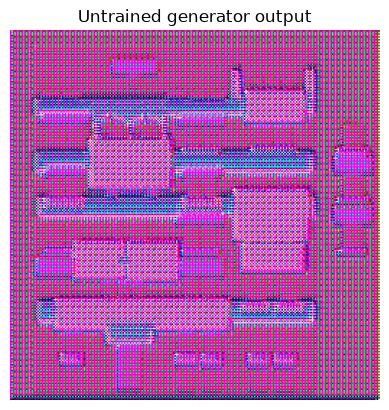

In [9]:
gen_output = generator(inp[tf.newaxis, ...], training=False)
plt.imshow(gen_output[0] * 0.5 + 0.5); plt.title("Untrained generator output"); plt.axis("off"); plt.show()

### Generator loss
`total = gan_loss + LAMBDA * l1_loss`, with `LAMBDA = 100`.
- GAN loss: BCE between discriminator output on fakes and an array of **ones**.
- L1 loss: mean absolute error between generated and target image.

In [10]:
LAMBDA = 100
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(disc_generated_output, gen_output, target):
    gan_loss = loss_object(tf.ones_like(disc_generated_output), disc_generated_output)
    l1_loss = tf.reduce_mean(tf.abs(target - gen_output))
    total_gen_loss = gan_loss + (LAMBDA * l1_loss)
    return total_gen_loss, gan_loss, l1_loss

## 5. Discriminator (PatchGAN)
Takes `[input, target]` concatenated; outputs a `30x30x1` map where each cell judges a **70x70 patch**.

Discriminator output shape: (1, 30, 30, 1)


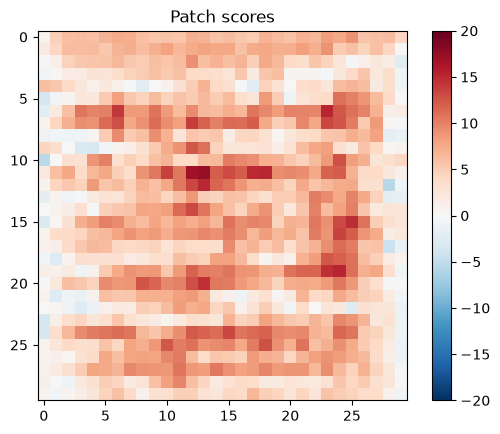

In [11]:
def Discriminator():
    initializer = tf.random_normal_initializer(0., 0.02)
    inp = tf.keras.layers.Input(shape=[256, 256, 3], name="input_image")
    tar = tf.keras.layers.Input(shape=[256, 256, 3], name="target_image")
    x = tf.keras.layers.concatenate([inp, tar])               # 256x256x6

    down1 = downsample(64, 4, False)(x)                       # 128x128x64
    down2 = downsample(128, 4)(down1)                         # 64x64x128
    down3 = downsample(256, 4)(down2)                         # 32x32x256

    zero_pad1 = tf.keras.layers.ZeroPadding2D()(down3)        # 34x34x256
    conv = tf.keras.layers.Conv2D(512, 4, strides=1, kernel_initializer=initializer,
                                  use_bias=False)(zero_pad1)  # 31x31x512
    batchnorm1 = tf.keras.layers.BatchNormalization()(conv)
    leaky_relu = tf.keras.layers.LeakyReLU()(batchnorm1)
    zero_pad2 = tf.keras.layers.ZeroPadding2D()(leaky_relu)   # 33x33x512
    last = tf.keras.layers.Conv2D(1, 4, strides=1, kernel_initializer=initializer)(zero_pad2)  # 30x30x1
    return tf.keras.Model(inputs=[inp, tar], outputs=last)

discriminator = Discriminator()
disc_out = discriminator([inp[tf.newaxis, ...], gen_output], training=False)
print("Discriminator output shape:", disc_out.shape)
plt.imshow(disc_out[0, ..., -1], vmin=-20, vmax=20, cmap="RdBu_r"); plt.colorbar(); plt.title("Patch scores"); plt.show()

In [12]:
def discriminator_loss(disc_real_output, disc_generated_output):
    real_loss = loss_object(tf.ones_like(disc_real_output), disc_real_output)
    generated_loss = loss_object(tf.zeros_like(disc_generated_output), disc_generated_output)
    return real_loss + generated_loss

## 6. Optimizers and checkpoints

In [13]:
generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

checkpoint_dir = "./training_checkpoints"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(generator_optimizer=generator_optimizer,
                                 discriminator_optimizer=discriminator_optimizer,
                                 generator=generator, discriminator=discriminator)

## 7. Helper to visualise results
`training=True` is intentional: it uses batch statistics (as in the paper) instead of running statistics.

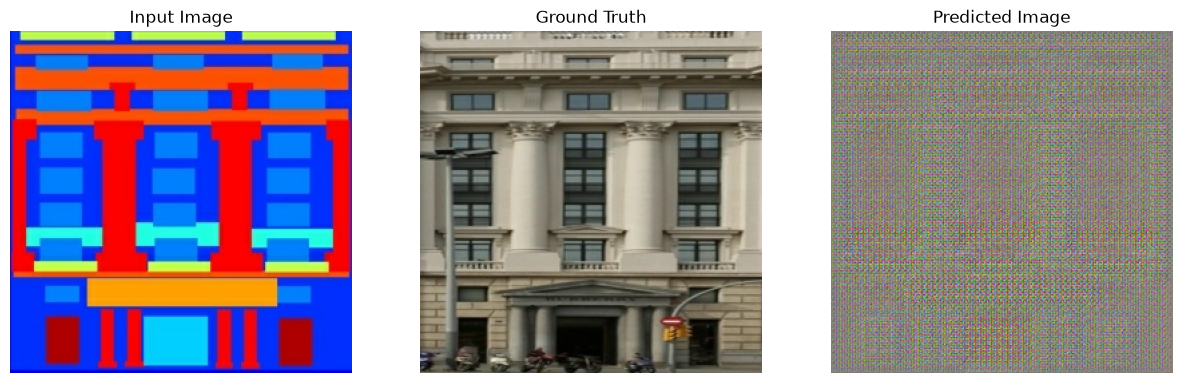

In [14]:
def generate_images(model, test_input, tar, save_path=None):
    prediction = model(test_input, training=True)
    plt.figure(figsize=(15, 5))
    display_list = [test_input[0], tar[0], prediction[0]]
    title = ["Input Image", "Ground Truth", "Predicted Image"]
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.title(title[i])
        plt.imshow(display_list[i] * 0.5 + 0.5)
        plt.axis("off")
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=100, bbox_inches="tight")
    plt.show()

for example_input, example_target in test_dataset.take(1):
    generate_images(generator, example_input, example_target)

## 8. Training
Each step: generate -> discriminator scores real and fake pairs -> compute both losses -> update both networks. Losses are logged to TensorBoard.

In [15]:
log_dir = "logs/"
summary_writer = tf.summary.create_file_writer(log_dir + "fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))

@tf.function
def train_step(input_image, target, step):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        gen_output = generator(input_image, training=True)
        disc_real_output = discriminator([input_image, target], training=True)
        disc_generated_output = discriminator([input_image, gen_output], training=True)

        gen_total_loss, gen_gan_loss, gen_l1_loss = generator_loss(disc_generated_output, gen_output, target)
        disc_loss = discriminator_loss(disc_real_output, disc_generated_output)

    generator_gradients = gen_tape.gradient(gen_total_loss, generator.trainable_variables)
    discriminator_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    generator_optimizer.apply_gradients(zip(generator_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(discriminator_gradients, discriminator.trainable_variables))

    with summary_writer.as_default():
        tf.summary.scalar("gen_total_loss", gen_total_loss, step=step // 1000)
        tf.summary.scalar("gen_gan_loss", gen_gan_loss, step=step // 1000)
        tf.summary.scalar("gen_l1_loss", gen_l1_loss, step=step // 1000)
        tf.summary.scalar("disc_loss", disc_loss, step=step // 1000)
    return gen_total_loss, gen_gan_loss, gen_l1_loss, disc_loss

In [16]:
history = {"gen_total": [], "gen_gan": [], "gen_l1": [], "disc": []}

def fit(train_ds, test_ds, steps):
    example_input, example_target = next(iter(test_ds.take(1)))
    start = time.time()
    for step, (input_image, target) in enumerate(train_ds.repeat().take(steps)):
        if step % 1000 == 0:
            display.clear_output(wait=True)
            if step != 0:
                print(f"Time taken for 1000 steps: {time.time() - start:.2f} sec\n")
            start = time.time()
            generate_images(generator, example_input, example_target,
                            save_path=f"../outputs/progress_step_{step:06d}.png")
            print(f"Step: {step // 1000}k")

        g_total, g_gan, g_l1, d_loss = train_step(input_image, target, tf.constant(step, dtype=tf.int64))
        if (step + 1) % 100 == 0:
            history["gen_total"].append(float(g_total)); history["gen_gan"].append(float(g_gan))
            history["gen_l1"].append(float(g_l1));       history["disc"].append(float(d_loss))
            print(".", end="", flush=True)
        if (step + 1) % 5000 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
    checkpoint.save(file_prefix=checkpoint_prefix)

In [17]:
# Optional: monitor with TensorBoard
%load_ext tensorboard
%tensorboard --logdir logs/

ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

In [22]:
print("Generator exists:", "generator" in globals())
print("Discriminator exists:", "discriminator" in globals())
print("Training dataset exists:", "train_dataset" in globals())

Generator exists: True
Discriminator exists: True
Training dataset exists: True


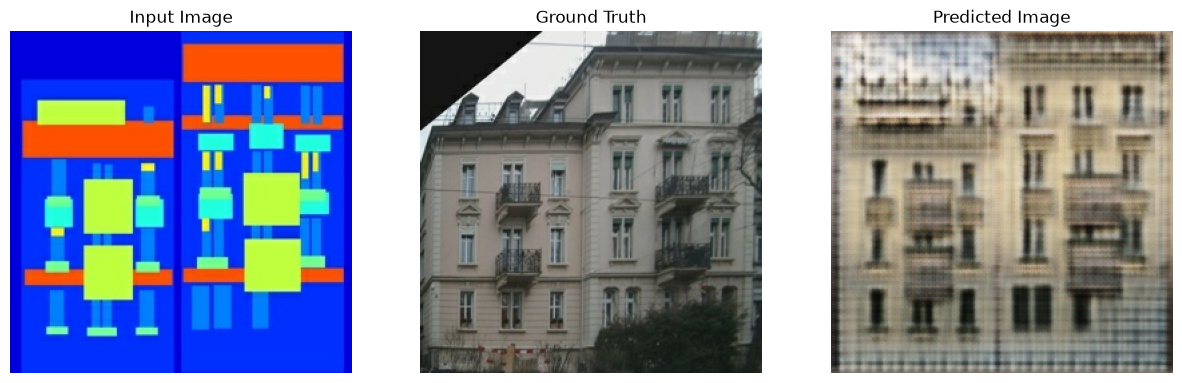

Step: 0k
.

In [23]:
STEPS = 100
fit(train_dataset, test_dataset, steps=STEPS)

### Reading the losses
- `log(2) = 0.69` is the reference value: the discriminator is equally unsure about real and fake.
- `disc_loss` far below 0.69 -> the discriminator is dominating; `gen_gan_loss` very low -> the generator is dominating. Neither should "win".
- `gen_l1_loss` should keep decreasing.
- Always judge GANs by looking at images, not only by loss values.

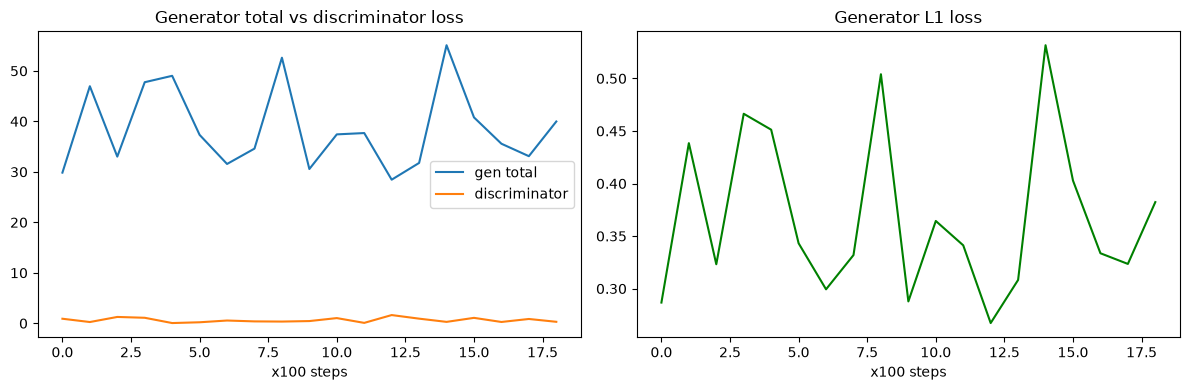

In [20]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history["gen_total"], label="gen total"); plt.plot(history["disc"], label="discriminator")
plt.xlabel("x100 steps"); plt.legend(); plt.title("Generator total vs discriminator loss")
plt.subplot(1, 2, 2)
plt.plot(history["gen_l1"], color="green"); plt.xlabel("x100 steps"); plt.title("Generator L1 loss")
plt.tight_layout(); plt.savefig("../outputs/loss_curves.png", dpi=120); plt.show()

## 9. Restore the latest checkpoint and test

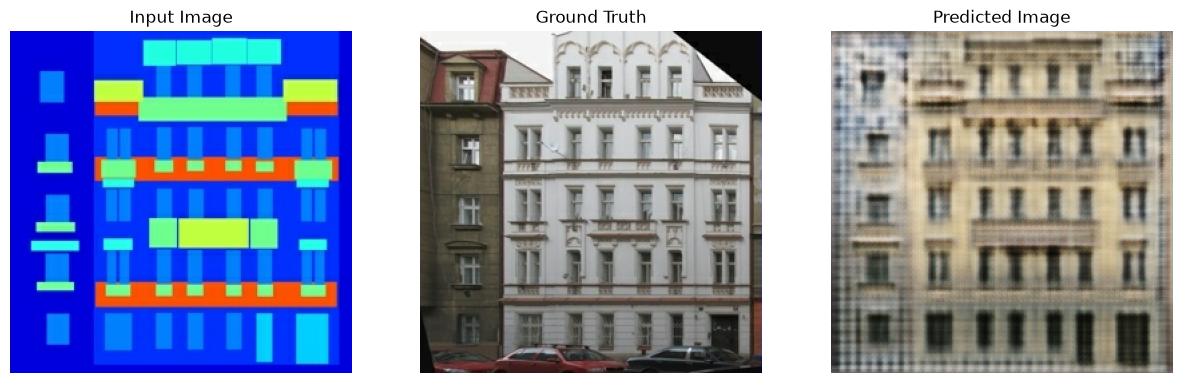

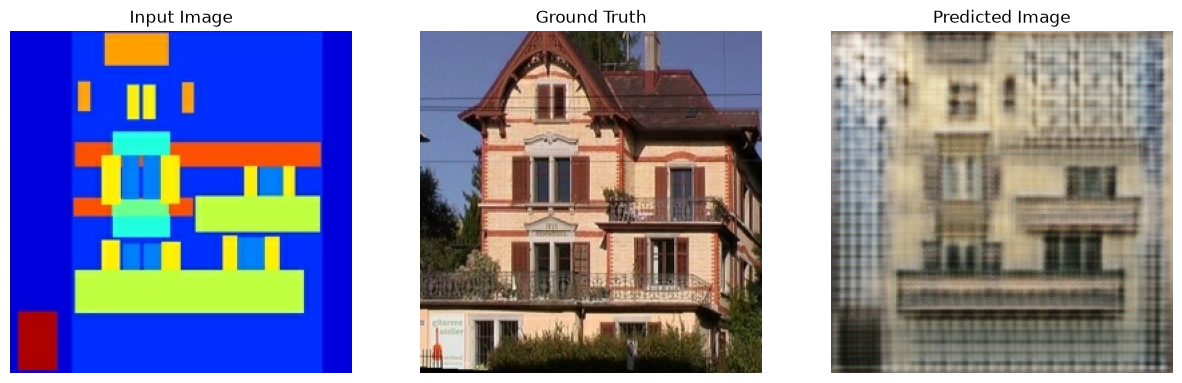

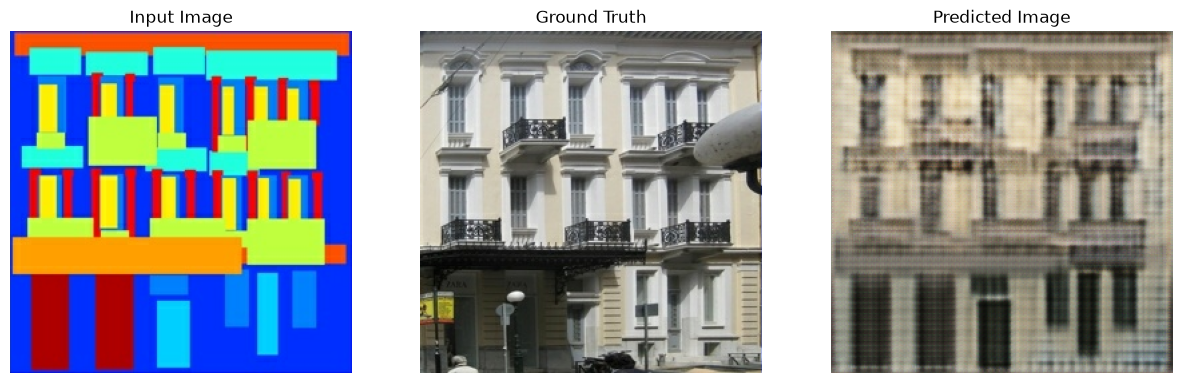

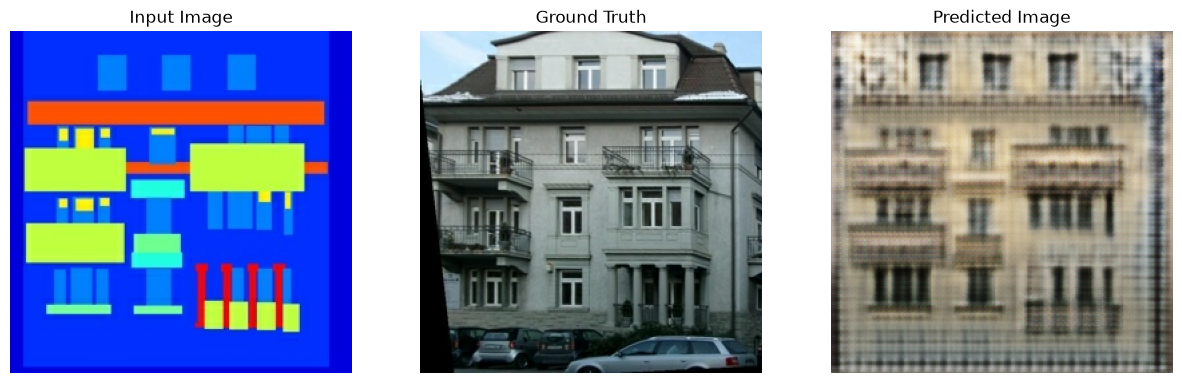

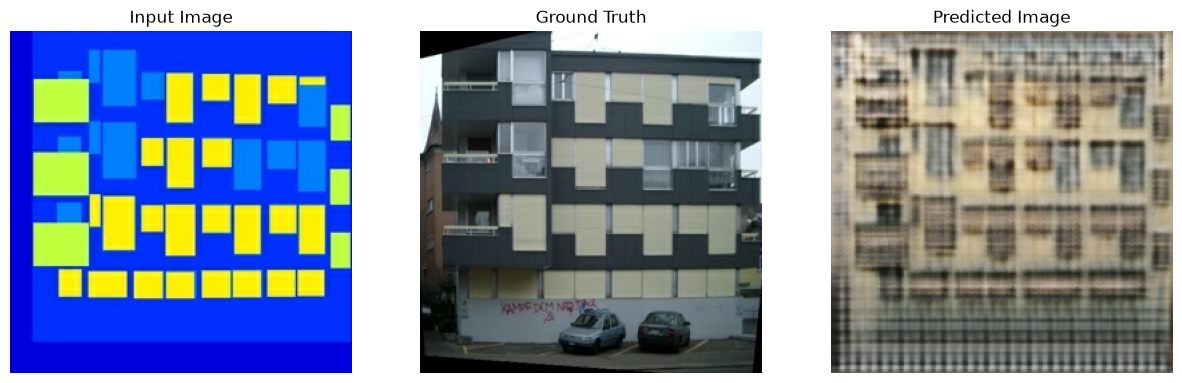

In [21]:
checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))
for i, (inp_, tar_) in enumerate(test_dataset.take(5)):
    generate_images(generator, inp_, tar_, save_path=f"../outputs/test_result_{i}.png")

## 10. Conclusion
- pix2pix is a **conditional GAN**: both networks see the input image, so the output is tied to the input.
- The **U-Net generator** with skip connections preserves spatial detail; the **PatchGAN discriminator** enforces local realism.
- **L1 loss (x100)** keeps outputs structurally correct while the **GAN loss** adds sharpness.
- More training steps give clearer facades; results are limited by the small dataset (400 images).
- Same code works for other paired datasets (`maps`, `cityscapes`, `edges2shoes`, ...) by changing `dataset_name`.

*Replace this section with your own observations from your outputs.*